In [1]:
import os
import sys

current_path = os.path.abspath(os.getcwd())
base_path = os.path.abspath(os.path.join(current_path, '../../../../'))
sys.path.append(base_path)

import numpy as np
import matplotlib.pyplot as plt  
import pandas as pd
from IPython.display import display


import project_images_loader as pil
from tqdm import tqdm

import utils.util as util
import utils.functions as fc
import utils.nifti_functions as nfc

import SimpleITK as sitk
import test_code.dfield_approach_elastix.constants as cts
# import metrics_computer as metrics_computer

import utils.util_freesurfer_segmentation as ufs

# np.set_printoptions(precision=4)


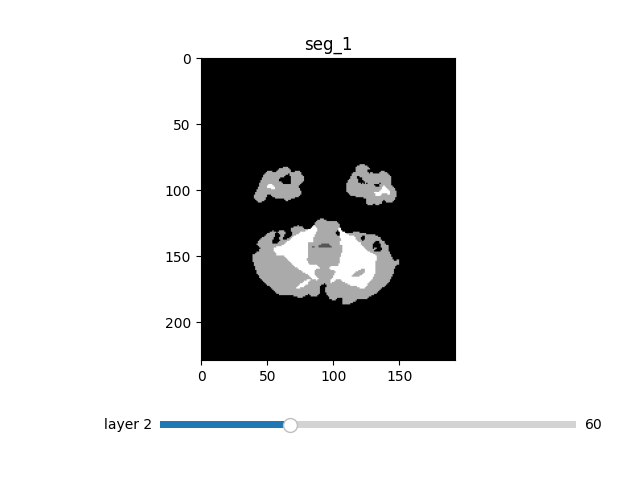

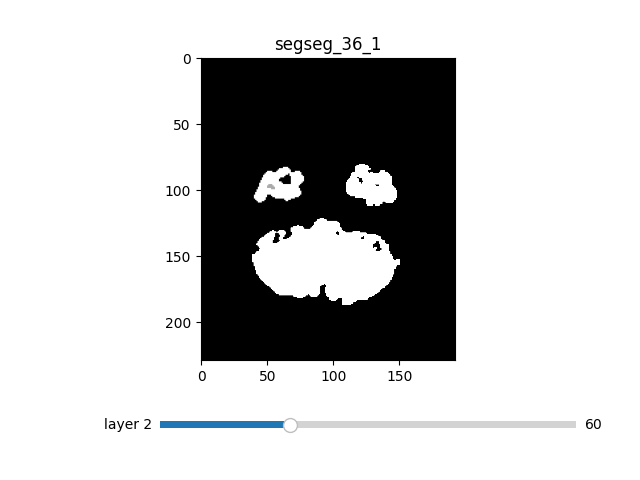

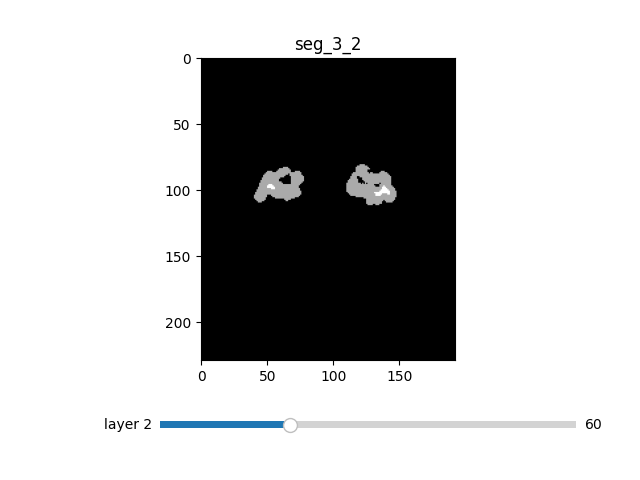

In [2]:
%matplotlib widget

matching_ids = pil.get_matching_ids()
seg_3, _ = nfc.load_nifti(pil.get_segmentation_path_name(3, matching_ids[0], 3, absolute=True))
seg_36, _ = nfc.load_nifti(pil.get_segmentation_path_name(3, matching_ids[0], 36, absolute=True))
seg_3_2 = ufs.remove_no_interesting_regions(seg_3, seg_36)

fc.imgshow_3D("seg_1", seg_3, current_plane=60, range_values=(0, 3))
fc.imgshow_3D("segseg_36_1", seg_36, current_plane=60, range_values=(0, 3))
fc.imgshow_3D("seg_3_2", seg_3_2, current_plane=60, range_values=(0, 3))


105298804
3324180
106657672


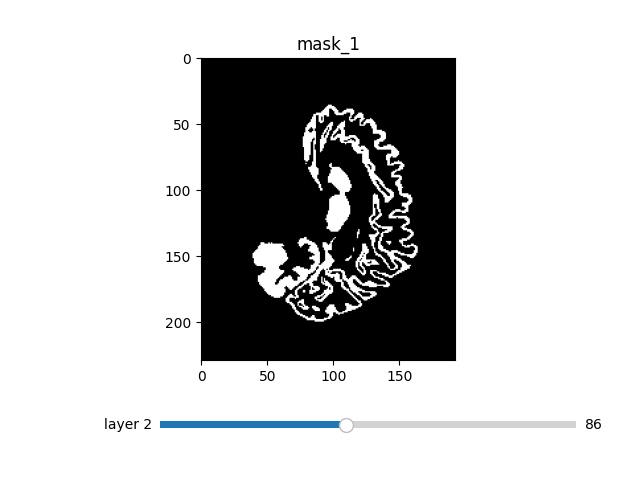

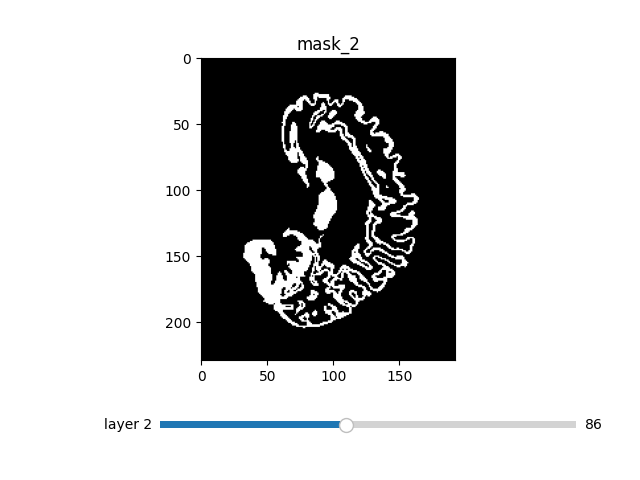

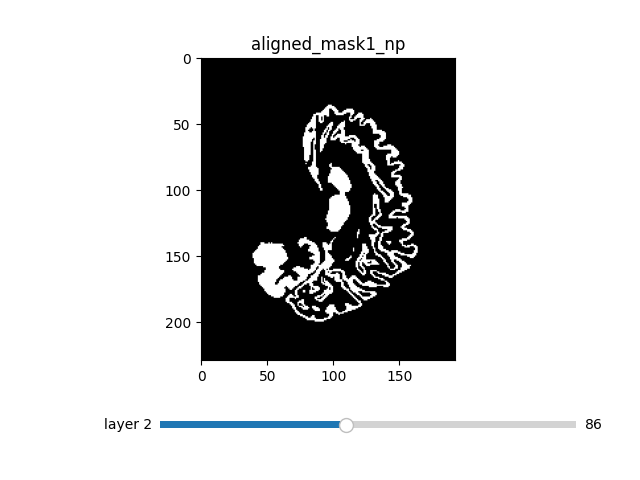

In [20]:

# # Supongamos que tienes dos máscaras 3D: mask1 y mask2
# # Aquí creamos máscaras 3D aleatorias como ejemplo
# %matplotlib widget

# matching_ids = pil.get_matching_ids()
# seg_1, seg_1_sitk = nfc.load_image_sitk(pil.get_segmentation_path_name(3, matching_ids[0], 3, absolute=True))
# seg_2, seg_2_sitk = nfc.load_image_sitk(pil.get_segmentation_path_name(3, matching_ids[1], 3, absolute=True))

# # seg_1 = seg_1.astype(np.uint8)
# # seg_2 = seg_2.astype(np.uint8)

# mask_1 = (seg_1 == 2).astype(np.uint8)
# mask_2 = (seg_2 == 2).astype(np.uint8)

# mask_1_sitk = sitk.GetImageFromArray(mask_1)
# mask_2_sitk = sitk.GetImageFromArray(mask_2)



# # Aplicar registro utilizando SimpleITK
# registration_method = sitk.ImageRegistrationMethod()

# # Configurar las opciones de registro
# registration_method.SetMetricAsMattesMutualInformation()
# registration_method.SetOptimizerAsRegularStepGradientDescent(learningRate=2.0,
#                                                              minStep=0.01,
#                                                              numberOfIterations=100,
#                                                              gradientMagnitudeTolerance=1e-6)
# registration_method.SetOptimizerScalesFromPhysicalShift()
# registration_method.SetInterpolator(sitk.sitkLinear)

# # Realizar el registro
# final_transform = registration_method.Execute(sitk.Cast(mask_1_sitk, sitk.sitkFloat32),
#                                               sitk.Cast(mask_2_sitk, sitk.sitkFloat32))

# # Aplicar la transformación alineada a la primera máscara
# aligned_mask1 = sitk.Resample(mask_1_sitk, mask_2_sitk, final_transform, sitk.sitkLinear, 0.0, mask_1_sitk.GetPixelID())

# # Convertir a array numpy para visualizar
# aligned_mask1_np = sitk.GetArrayFromImage(aligned_mask1)

# # # Imprimir la primera máscara alineada (puedes visualizarla utilizando herramientas como matplotlib o una aplicación de visualización de imágenes médicas)
# print(np.sum(mask_1-mask_2))
# print(np.sum(aligned_mask1_np-mask_1))
# print(np.sum(aligned_mask1_np-mask_2))

# fc.imgshow_3D("mask_1", mask_1, current_plane=86, range_values=(0, 1))
# fc.imgshow_3D("mask_2", mask_2, current_plane=86, range_values=(0, 1))
# fc.imgshow_3D("aligned_mask1_np", aligned_mask1_np, current_plane=86, range_values=(0, 1))
